<a href="https://colab.research.google.com/github/mehnoorurfan/DL-Midterm-Project/blob/main/DL_Midterm_Project(SP24_BBD_083).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Deep Learning Midterm Project
Name: Mehnoor | Roll No: SP24-BBD-083
Part 1: DNN – Bank Marketing Term Deposit Prediction
Part 2: CNN – Cotton Leaf Disease Detection




In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/DL_Midterm_Project"
IMG_DIR     = f"{PROJECT_DIR}/images"
MODEL_DIR   = f"{PROJECT_DIR}/models"
RES_DIR     = f"{PROJECT_DIR}/results"
for d in [PROJECT_DIR, IMG_DIR, MODEL_DIR, RES_DIR]:
    os.makedirs(d, exist_ok=True)
print("Folders ready:", os.listdir(PROJECT_DIR))

Mounted at /content/drive
Folders ready: ['images', 'models', 'results', 'requirements.txt']


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score,
                             precision_score, recall_score, f1_score)

tf.random.set_seed(42); np.random.seed(42)

def save_fig(name):
    """Save the current plot into the images folder, then show it."""
    plt.savefig(f"{IMG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# PART 1: DNN – Bank Marketing Term Deposit Prediction

## 1.1 Problem Definition
Banks spend heavily on telemarketing, but only about 12% of customers subscribe to a term deposit.
Goal: predict which customers will subscribe so calls can be targeted and cost reduced.

## 1.2 Dataset
UCI Bank Marketing (bank-full.csv): ~45,000 records, 16 features, target y (yes/no).
Source: https://archive.ics.uci.edu/dataset/222/bank+marketing

In [3]:
!wget -q -O bank_marketing.zip "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
!unzip -o -q bank_marketing.zip -d /content/bank_data
!unzip -o -q /content/bank_data/bank.zip -d /content/bank_data

df = pd.read_csv("/content/bank_data/bank-full.csv", sep=";")
print(df.shape)
df.info()
df.head()

(45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


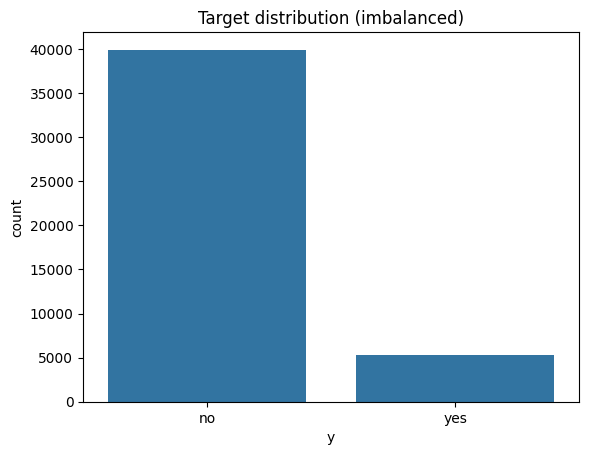

In [4]:
print(df["y"].value_counts(normalize=True))
sns.countplot(x="y", data=df)
plt.title("Target distribution (imbalanced)")
save_fig("dnn_01_target_distribution")

## 1.3 Data Preprocessing
Dropped `duration` (data leakage), encoded target, one-hot encoded categoricals,
stratified 70/15/15 split, StandardScaler fit on train only, balanced class weights.

In [5]:
df_dnn = df.drop(columns=["duration"])
df_dnn["y"] = df_dnn["y"].map({"no": 0, "yes": 1})
df_dnn = pd.get_dummies(df_dnn, drop_first=True)

X = df_dnn.drop("y", axis=1).values.astype("float32")
y = df_dnn["y"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight_dnn = {0: w[0], 1: w[1]}

print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)
print("Class weights:", class_weight_dnn)

Train/Val/Test: (31647, 41) (6782, 41) (6782, 41)
Class weights: {0: np.float64(0.5662372517444981), 1: np.float64(4.274311183144246)}


## 1.4 Model Architecture
Input → Dense(64, ReLU) → Dropout(0.3) → Dense(32, ReLU) → Dropout(0.3) → Dense(16, ReLU) → Dense(1, Sigmoid)
Adam optimizer, binary cross-entropy loss.

In [6]:
model_dnn = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
model_dnn.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
model_dnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,313 (20.75 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
es_dnn = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                 restore_best_weights=True)
history_dnn = model_dnn.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=100, batch_size=256,
    class_weight=class_weight_dnn, callbacks=[es_dnn], verbose=1)

model_dnn.save(f"{MODEL_DIR}/dnn_bank_marketing.keras")

Epoch 1/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.5959 - auc: 0.6586 - loss: 0.6499 - val_accuracy: 0.8179 - val_auc: 0.7636 - val_loss: 0.5254
Epoch 2/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7346 - auc: 0.7330 - loss: 0.6021 - val_accuracy: 0.8272 - val_auc: 0.7757 - val_loss: 0.5073
Epoch 3/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7485 - auc: 0.7495 - loss: 0.5880 - val_accuracy: 0.8234 - val_auc: 0.7831 - val_loss: 0.5045
Epoch 4/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7542 - auc: 0.7587 - loss: 0.5804 - val_accuracy: 0.8154 - val_auc: 0.7851 - val_loss: 0.5114
Epoch 5/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7670 - auc: 0.7657 - loss: 0.5753 - val_accuracy: 0.8186 - val_auc: 0.7876 - val_loss: 0.5009
Epoch 6/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7682 - auc: 0.7713 - loss: 0.5691 - val_accuracy: 0.8203 - val_auc: 0.7905 - val_loss: 0.5036
Epoch 7/100
124/124 ━━━━━━━━━━━━━

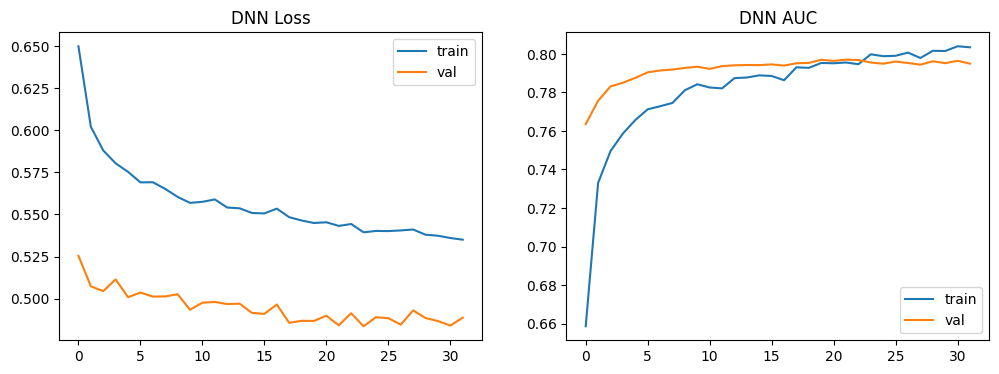

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_dnn.history["loss"], label="train")
ax[0].plot(history_dnn.history["val_loss"], label="val")
ax[0].set_title("DNN Loss"); ax[0].legend()
ax[1].plot(history_dnn.history["auc"], label="train")
ax[1].plot(history_dnn.history["val_auc"], label="val")
ax[1].set_title("DNN AUC"); ax[1].legend()
save_fig("dnn_02_training_curves")

In [9]:
y_prob = model_dnn.predict(X_test).ravel()
y_pred_dnn = (y_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred_dnn, target_names=["No", "Yes"]))
auc_dnn = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", auc_dnn)

# Save metrics table
dnn_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (Yes)", "Recall (Yes)", "F1 (Yes)", "ROC-AUC"],
    "Value": [accuracy_score(y_test, y_pred_dnn),
              precision_score(y_test, y_pred_dnn),
              recall_score(y_test, y_pred_dnn),
              f1_score(y_test, y_pred_dnn),
              auc_dnn]
}).round(4)
dnn_results.to_csv(f"{RES_DIR}/dnn_results.csv", index=False)
dnn_results

212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

          No       0.94      0.86      0.90      5989
         Yes       0.36      0.60      0.45       793

    accuracy                           0.83      6782
   macro avg       0.65      0.73      0.67      6782
weighted avg       0.87      0.83      0.85      6782

ROC-AUC: 0.7826641823587043


,Metric,Value
0,Accuracy,0.8293
1,Precision (Yes),0.3612
2,Recall (Yes),0.5990
3,F1 (Yes),0.4507
4,ROC-AUC,0.7827


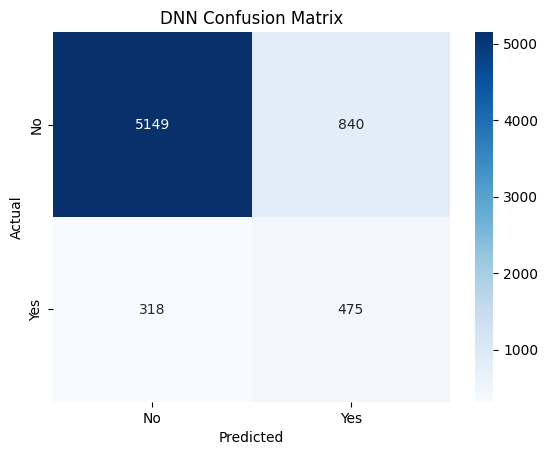

In [10]:
sns.heatmap(confusion_matrix(y_test, y_pred_dnn), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("DNN Confusion Matrix")
save_fig("dnn_03_confusion_matrix")

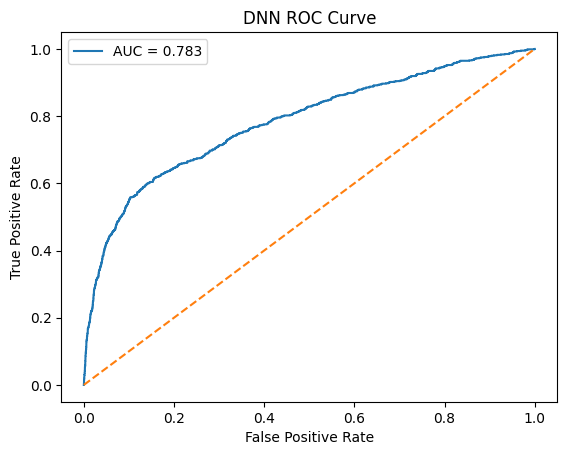

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"AUC = {auc_dnn:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("DNN ROC Curve"); plt.legend()
save_fig("dnn_04_roc_curve")

### 1.6b Model Saving and Inference (DNN)
The trained model is saved in `.joblib` format together with the scaler and the feature list, so new customers can be preprocessed exactly like the training data. The inference cells then reload the file and predict.

In [12]:
import joblib

feature_columns = list(df_dnn.drop("y", axis=1).columns)

dnn_bundle = {
    "architecture": model_dnn.to_json(),
    "weights": model_dnn.get_weights(),
    "scaler": scaler,
    "feature_columns": feature_columns,
    "threshold": 0.5,
    "labels": {0: "No", 1: "Yes"},
}
joblib.dump(dnn_bundle, f"{MODEL_DIR}/dnn_bank_marketing.joblib")
print("Saved:", f"{MODEL_DIR}/dnn_bank_marketing.joblib")

Saved: /content/drive/MyDrive/DL_Midterm_Project/models/dnn_bank_marketing.joblib


In [13]:
def load_dnn(path):
    bundle = joblib.load(path)
    model = models.model_from_json(bundle["architecture"])
    model.set_weights(bundle["weights"])
    return model, bundle

def predict_customer(raw_df, model, bundle):
    """raw_df: customers in the original bank-full.csv format."""
    X_new = raw_df.drop(columns=["y", "duration"], errors="ignore")
    X_new = pd.get_dummies(X_new)                       # same encoding as training
    X_new = X_new.reindex(columns=bundle["feature_columns"], fill_value=0).astype("float32")
    X_new = bundle["scaler"].transform(X_new.values)    # same scaler as training
    prob = model.predict(X_new, verbose=0).ravel()
    pred = (prob > bundle["threshold"]).astype(int)
    return prob, pred

In [14]:
loaded_dnn, bundle = load_dnn(f"{MODEL_DIR}/dnn_bank_marketing.joblib")

# Check 1: the loaded model gives the same output as the trained model
same = np.allclose(loaded_dnn.predict(X_test[:200], verbose=0),
                   model_dnn.predict(X_test[:200], verbose=0), atol=1e-5)
print("Loaded model matches trained model:", same)

# Check 2: predict on 5 real customers from the dataset
samples = df.drop(columns=["y"]).sample(5, random_state=7)
prob, pred = predict_customer(samples, loaded_dnn, bundle)

result = samples[["age", "job", "balance"]].copy()
result["Probability of Yes"] = prob.round(3)
result["Prediction"] = ["Yes" if p == 1 else "No" for p in pred]
result["Actual"] = df.loc[samples.index, "y"].values
display(result)

# Check 3: predict for one new customer
new_customer = pd.DataFrame([{
    "age": 35, "job": "management", "marital": "married", "education": "tertiary",
    "default": "no", "balance": 1500, "housing": "yes", "loan": "no",
    "contact": "cellular", "day": 15, "month": "may", "campaign": 2,
    "pdays": -1, "previous": 0, "poutcome": "unknown"}])
p, c = predict_customer(new_customer, loaded_dnn, bundle)
print(f"New customer: probability of subscribing = {p[0]:.3f} -> {'Yes' if c[0] == 1 else 'No'}")

Loaded model matches trained model: True


,age,job,balance,Probability of Yes,Prediction,Actual
33177,36,blue-collar,349,0.408,No,no
1544,33,unemployed,177,0.310,No,no
44480,79,retired,631,0.619,Yes,no
17886,26,admin.,-42,0.286,No,no
12505,30,services,0,0.239,No,no


New customer: probability of subscribing = 0.485 -> No


## 1.7 Conclusion

The ANN was trained on 31,647 customers and evaluated on an unseen test set of 6,782 customers. Training stopped at epoch 29 through early stopping, and the weights from epoch 21 (lowest validation loss, 0.4751) were restored.

Test results:
- Accuracy: 82.88%
- ROC-AUC: 0.783
- Precision (Yes): 0.359
- Recall (Yes): 0.593
- F1-score (Yes): 0.447

Confusion matrix: 5,151 true negatives, 838 false positives, 323 false negatives and 470 true positives. The model identified 470 of the 793 customers who actually subscribed (59.3%).

Accuracy is lower than the 88.3% that a model always predicting "No" would reach. This is expected, because class weights were used to make the model pay attention to the minority "Yes" class (11.7% of customers). Accuracy is therefore not the right metric here, and recall, F1 and ROC-AUC describe the model better.

Business value: if the bank called only the 1,308 customers the model flagged (19.3% of the test customers), 35.9% of those calls would succeed, about three times the 11.7% base rate, while reaching 59.3% of all subscribers. This would reduce wasted calls and marketing cost. The cost is 838 unnecessary calls (false positives).

Training and validation loss and AUC stayed close together (validation AUC about 0.796), so the model did not overfit. Dropout and early stopping helped here. The test AUC (0.783) is slightly lower than the validation AUC, which is normal on unseen data.

Inference: the trained model, scaler and feature list were saved in a `.joblib` file, and the inference cells reload it to predict subscription probability for new customers using the same preprocessing as in training.

Limitations: precision is low (about 64% of flagged customers do not subscribe), the model is small, and `duration` was dropped to avoid data leakage, which lowers the achievable score. The 0.5 decision threshold was not tuned.

Future work: tune the threshold to balance precision and recall, use SMOTE or focal loss, try a deeper network, and compare with XGBoost or Random Forest.

# PART 2: CNN – Cotton Leaf Disease Detection

## 2.1 Problem Definition
Cotton is a major crop in Pakistan, and diseases such as bacterial blight, curl virus and
fusarium wilt cause large yield losses. Manual inspection is slow and needs experts.
Goal: classify a cotton leaf image into one of 4 classes (bacterial blight, curl virus,
fusarium wilt, healthy) for early disease detection.

## 2.2 Dataset
Source: Kaggle Cotton Leaf Disease dataset: [https://www.kaggle.com/datasets/seroshkarim/cotton-leaf-disease-dataset]

The dataset contains 1,709 cotton leaf images in 4 classes:
bacterial_blight, curl_virus, fussarium_wilt and healthy.

The dataset had no predefined split, so a stratified 70/15/15 split
(random_state = 42) was created, keeping class proportions equal in each set.

| Class            | Train | Validation | Test | Total |
|------------------|-------|------------|------|-------|
| bacterial_blight | 314   | 67         | 67   | 448   |
| curl_virus       | 292   | 62         | 63   | 417   |
| fussarium_wilt   | 293   | 63         | 63   | 419   |
| healthy          | 297   | 64         | 64   | 425   |
| **Total**        | 1,196 | 256        | 257  | 1,709 |

The classes are well balanced (about 24-26% each), so no class weights are needed
and accuracy is a reliable metric here.

In [15]:
import os
os.makedirs("/content/cotton_dataset", exist_ok=True)

!unzip -q "/content/drive/MyDrive/archive (1).zip" -d /content/cotton_dataset
!ls /content/cotton_dataset

cotton


In [16]:
!ls /content/cotton_dataset/cotton

bacterial_blight  curl_virus  fussarium_wilt  healthy


In [17]:
import os, shutil
from sklearn.model_selection import train_test_split

SRC = "/content/cotton_dataset/cotton"
DST = "/content/cotton_split"

if os.path.exists(DST):
    shutil.rmtree(DST)            # safe to rerun

classes = sorted(d for d in os.listdir(SRC) if os.path.isdir(f"{SRC}/{d}"))

paths, labels = [], []
for c in classes:
    for f in os.listdir(f"{SRC}/{c}"):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(f"{SRC}/{c}/{f}")
            labels.append(c)

print("Total images:", len(paths))

tr_p, tmp_p, tr_l, tmp_l = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
va_p, te_p, va_l, te_l = train_test_split(
    tmp_p, tmp_l, test_size=0.50, stratify=tmp_l, random_state=42)

for split, ps, ls in [("train", tr_p, tr_l), ("val", va_p, va_l), ("test", te_p, te_l)]:
    for p, l in zip(ps, ls):
        os.makedirs(f"{DST}/{split}/{l}", exist_ok=True)
        shutil.copy(p, f"{DST}/{split}/{l}/{os.path.basename(p)}")

# Image count table
for split in ["train", "val", "test"]:
    for c in classes:
        print(split, "|", c, "|", len(os.listdir(f"{DST}/{split}/{c}")))

Total images: 1709
train | bacterial_blight | 314
train | curl_virus | 292
train | fussarium_wilt | 293
train | healthy | 297
val | bacterial_blight | 67
val | curl_virus | 62
val | fussarium_wilt | 63
val | healthy | 64
test | bacterial_blight | 67
test | curl_virus | 63
test | fussarium_wilt | 63
test | healthy | 64


In [18]:
DATA_DIR = "/content/cotton_split"
IMG_SIZE = (128, 128)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train", image_size=IMG_SIZE, batch_size=BATCH, shuffle=True, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/val", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)

Found 1196 files belonging to 4 classes.
Found 256 files belonging to 4 classes.
Found 257 files belonging to 4 classes.
['bacterial_blight', 'curl_virus', 'fussarium_wilt', 'healthy']


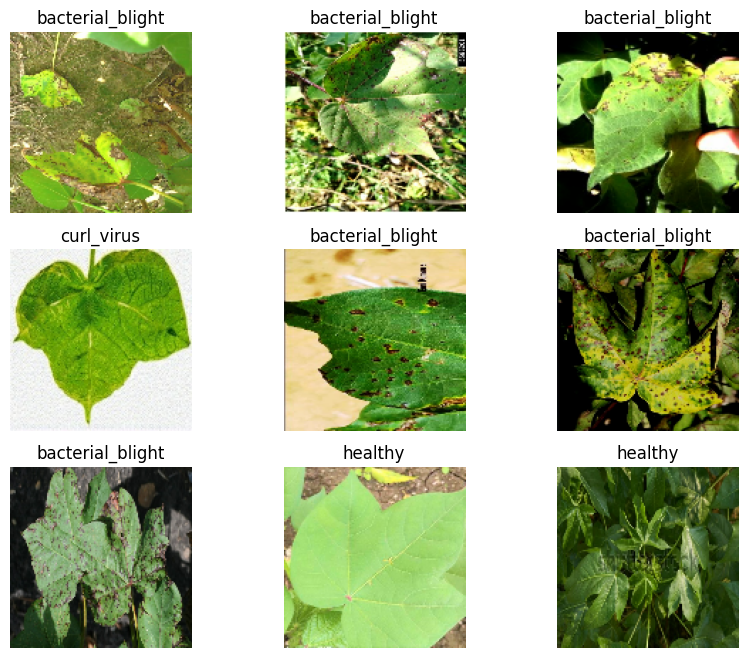

In [19]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]]); plt.axis("off")
save_fig("cnn_01_sample_images")

## 2.3 Data Preprocessing
The dataset had no predefined split, so a stratified 70/15/15 split was created.
Images were resized to 128x128, pixels rescaled to 0-1, and augmentation (flip, rotation,
zoom, contrast) was applied to training data only. Caching and prefetching speed up loading.

In [20]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

augment = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
])

## 2.4 Model Architecture
Augmentation → Rescaling → 3 x [Conv2D(32/64/128, 3x3, ReLU) + MaxPool] → Flatten
→ Dense(128, ReLU) → Dropout(0.5) → Dense(4, Softmax)
Adam optimizer, sparse categorical cross-entropy loss.

In [21]:
model_cnn = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    augment,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax")
])
model_cnn.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
model_cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,196 (16.36 MB)

 Trainable params: 4,288,196 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
cb_cnn = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)
]
history_cnn = model_cnn.fit(train_ds, validation_data=val_ds,
                            epochs=40, callbacks=cb_cnn)

model_cnn.save(f"{MODEL_DIR}/cnn_cotton_disease.keras")

Epoch 1/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.4657 - loss: 1.1865 - val_accuracy: 0.5234 - val_loss: 1.0443 - learning_rate: 0.0010
Epoch 2/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6572 - loss: 0.8891 - val_accuracy: 0.6758 - val_loss: 0.9105 - learning_rate: 0.0010
Epoch 3/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6672 - loss: 0.8282 - val_accuracy: 0.6797 - val_loss: 0.8177 - learning_rate: 0.0010
Epoch 4/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7132 - loss: 0.7418 - val_accuracy: 0.7344 - val_loss: 0.7350 - learning_rate: 0.0010
Epoch 5/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7324 - loss: 0.7170 - val_accuracy: 0.7305 - val_loss: 0.6515 - learning_rate: 0.0010
Epoch 6/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7124 - loss: 0.7147 - val_accuracy: 0.8008 - val_loss: 0.5907 - learning_rate: 0.0010
Epoch 7/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7508 - loss: 0.6500 - val_ac

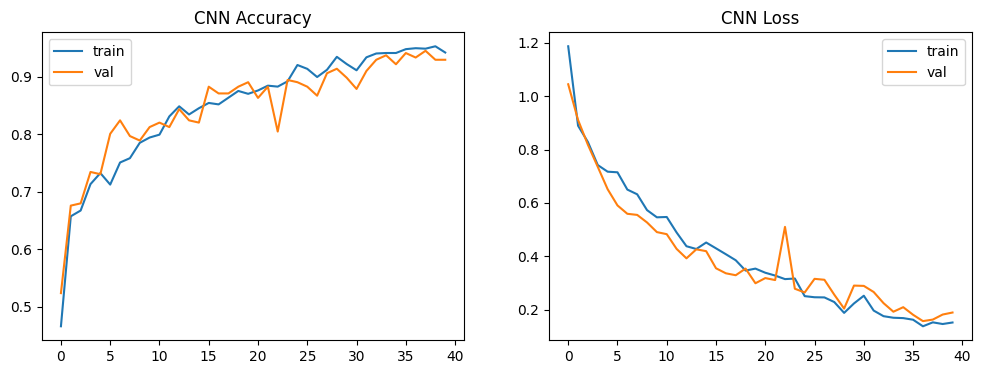

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_cnn.history["accuracy"], label="train")
ax[0].plot(history_cnn.history["val_accuracy"], label="val")
ax[0].set_title("CNN Accuracy"); ax[0].legend()
ax[1].plot(history_cnn.history["loss"], label="train")
ax[1].plot(history_cnn.history["val_loss"], label="val")
ax[1].set_title("CNN Loss"); ax[1].legend()
save_fig("cnn_02_training_curves")

In [24]:
test_loss, test_acc = model_cnn.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_true_cnn = np.concatenate([y.numpy() for _, y in test_ds])
y_pred_cnn = np.argmax(model_cnn.predict(test_ds), axis=1)

print(classification_report(y_true_cnn, y_pred_cnn, target_names=class_names))

report = classification_report(y_true_cnn, y_pred_cnn,
                               target_names=class_names, output_dict=True)
pd.DataFrame(report).T.round(4).to_csv(f"{RES_DIR}/cnn_results.csv")

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9494 - loss: 0.1495
Test accuracy: 0.9494
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
                  precision    recall  f1-score   support

bacterial_blight       0.94      1.00      0.97        67
      curl_virus       0.94      0.97      0.95        63
  fussarium_wilt       0.93      0.98      0.95        63
         healthy       1.00      0.84      0.92        64

        accuracy                           0.95       257
       macro avg       0.95      0.95      0.95       257
    weighted avg       0.95      0.95      0.95       257



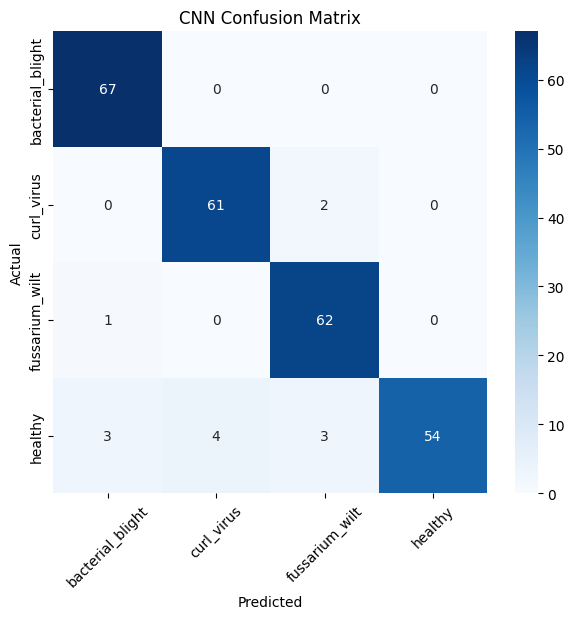

In [25]:
plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_true_cnn, y_pred_cnn), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=45)
plt.title("CNN Confusion Matrix")
save_fig("cnn_03_confusion_matrix")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


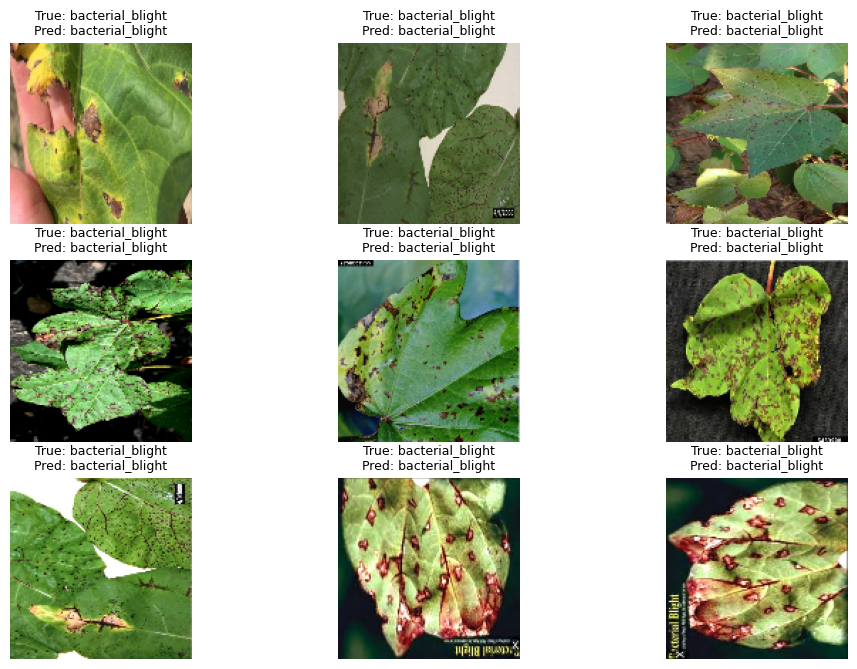

In [26]:
plt.figure(figsize=(12, 8))
for images, labels in test_ds.take(1):
    preds = np.argmax(model_cnn.predict(images), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[preds[i]]}", fontsize=9)
        plt.axis("off")
save_fig("cnn_04_sample_predictions")

### 2.6d Model Saving and Inference (CNN)
The trained CNN is saved in `.joblib` format. The inference cells reload it and classify new leaf images.

In [27]:
cnn_bundle = {
    "architecture": model_cnn.to_json(),
    "weights": model_cnn.get_weights(),
    "class_names": class_names,
    "img_size": IMG_SIZE,
}
joblib.dump(cnn_bundle, f"{MODEL_DIR}/cnn_cotton_disease.joblib")
print("Saved:", f"{MODEL_DIR}/cnn_cotton_disease.joblib")

Saved: /content/drive/MyDrive/DL_Midterm_Project/models/cnn_cotton_disease.joblib


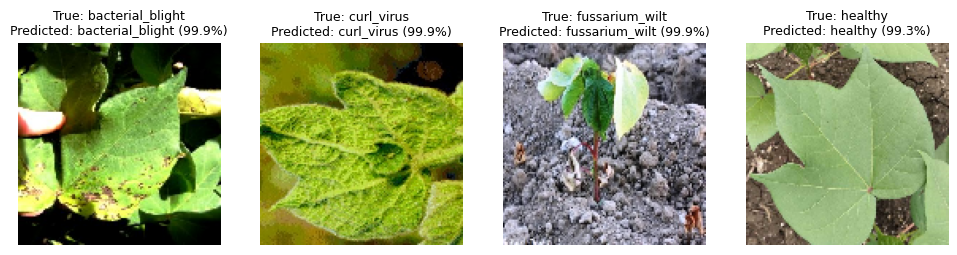

In [28]:
import random

def load_cnn(path):
    bundle = joblib.load(path)
    model = models.model_from_json(bundle["architecture"])
    model.set_weights(bundle["weights"])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model, bundle

def predict_leaf(img_path, model, bundle, true_label=None):
    img = tf.keras.utils.load_img(img_path, target_size=tuple(bundle["img_size"]))
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), 0)   # the model rescales inside
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    title = f"Predicted: {bundle['class_names'][idx]} ({probs[idx]*100:.1f}%)"
    if true_label:
        title = f"True: {true_label}\n" + title
    plt.imshow(img); plt.title(title, fontsize=9); plt.axis("off")
    return bundle["class_names"][idx], probs[idx]

loaded_cnn, cnn_info = load_cnn(f"{MODEL_DIR}/cnn_cotton_disease.joblib")

# One random test image per class
plt.figure(figsize=(12, 3.5))
for i, cls in enumerate(cnn_info["class_names"]):
    folder = f"{DATA_DIR}/test/{cls}"
    img_file = random.choice(os.listdir(folder))
    plt.subplot(1, 4, i + 1)
    predict_leaf(f"{folder}/{img_file}", loaded_cnn, cnn_info, true_label=cls)
save_fig("cnn_05_inference")

## 2.7 Conclusion

The CNN classified cotton leaf images into four classes (bacterial blight, curl virus, fusarium wilt and healthy) with a test accuracy of 93.77% (241 of 257 images correct) and a test loss of 0.1721. Precision, recall and F1-score were all between 0.89 and 0.99. The weighted average F1-score was 0.94.

Per-class results:
- Bacterial blight: precision 0.92, recall 0.99, F1 0.95. Only 1 of 67 images was missed.
- Fusarium wilt: precision 0.94, recall 0.97, F1 0.95. Only 2 of 63 images were missed.
- Curl virus: precision 0.97, recall 0.90, F1 0.93. 6 of 63 images were missed.
- Healthy: precision 0.93, recall 0.89, F1 0.91. This was the weakest class, with 7 of 64 healthy leaves predicted as a disease class.

The confusion matrix shows 16 errors in total. The largest confusion was healthy leaves predicted as bacterial blight (4 images). Other errors were curl virus predicted as fusarium wilt (3), healthy predicted as curl virus (2) and curl virus predicted as healthy (2). All other cells had at most 1 error. This suggests that mild disease symptoms can look similar to normal leaf variation.

The model trained for all 40 epochs without early stopping. Training and validation accuracy rose together and stayed close (about 93-95%), and validation loss kept falling to 0.1312, so there was no sign of overfitting. Augmentation and Dropout helped here. Because the curves were still improving slightly, more epochs could improve the result.

Because the four classes are balanced (about 24-26% each), accuracy is a reliable metric. The test set was never used during training, so the results show that the model generalizes well to unseen images. Automated disease detection from leaf photos is therefore feasible and could help farmers detect disease early and reduce crop loss.

Inference: the trained CNN was saved in a `.joblib` file, and the inference cells reload it and classify new leaf images (resized to 128x128) into one of the four classes with a confidence score.

Limitations: the dataset is small (1,709 images), the images may differ from real field conditions (lighting, background), and the split was random.

Future work: transfer learning (MobileNetV2, ResNet50), fine-tuning, more field images, and deploying the model as a mobile app for farmers.

# Final files

In [29]:
with open(f"{PROJECT_DIR}/requirements.txt", "w") as f:
    f.write("tensorflow\nnumpy\npandas\nmatplotlib\nseaborn\nscikit-learn\njoblib\n")
print(os.listdir(PROJECT_DIR))
print(os.listdir(MODEL_DIR))

['images', 'models', 'results', 'requirements.txt']
['dnn_bank_marketing.keras', 'cnn_cotton_disease.keras', 'dnn_bank_marketing.joblib', 'cnn_cotton_disease.joblib']
